# 06. In-Depth Model Evaluation

## Executive Summary
In churn prediction, Accuracy can be misleading due to class imbalance (73.5% non-churn). A business needs to evaluate models based on:
1. **Recall (Sensitivity):** Fraction of actual churners correctly caught. High recall avoids lost revenue.
2. **Precision:** Fraction of predicted churners who actually churn. High precision avoids wasted discount budget.
3. **F1-Score:** Harmonic mean balancing precision and recall.
4. **ROC-AUC:** Area under Receiver Operating Characteristic curve measuring rank discrimination across all decision thresholds.
5. **Confusion Matrix:** True Positives, False Positives, True Negatives, False Negatives.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test_raw = pd.read_csv("../data/processed/y_test.csv").squeeze()
y_test = y_test_raw.map({"No": 0, "Yes": 1}) if y_test_raw.dtype == object else y_test_raw

# Load baseline models
models = {
    "Logistic Regression": joblib.load("../models/logistic_regression.pkl"),
    "Decision Tree": joblib.load("../models/decision_tree.pkl"),
    "Random Forest": joblib.load("../models/random_forest.pkl"),
    "KNN": joblib.load("../models/knn.pkl"),
    "Naive Bayes": joblib.load("../models/naive_bayes.pkl"),
    "Support Vector Machine": joblib.load("../models/support_vector_machine.pkl"),
}
print(f"Loaded {len(models)} models for evaluation on {len(X_test)} test records.")

Loaded 6 models for evaluation on 1409 test records.


## 1. Computing Comprehensive Test Set Metrics

In [2]:
eval_records = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    if isinstance(y_pred[0], str):
        y_pred = np.array([1 if p == "Yes" else 0 for p in y_pred])
    predictions[name] = y_pred

    if hasattr(model, "predict_proba"):
        classes = list(getattr(model, "classes_", [0, 1]))
        pos_idx = classes.index(1) if 1 in classes else (classes.index("Yes") if "Yes" in classes else 1)
        y_prob = model.predict_proba(X_test)[:, pos_idx]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    probabilities[name] = y_prob

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    eval_records.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "ROC AUC": auc,
    })

eval_df = pd.DataFrame(eval_records).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
print("=== Baseline Model Evaluation on Independent Test Set ===")
display(eval_df.round(4))

=== Baseline Model Evaluation on Independent Test Set ===


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Naive Bayes,0.6948,0.4589,0.8369,0.5928,0.8074
2,KNN,0.7637,0.5527,0.5749,0.5636,0.7896
3,Support Vector Machine,0.7913,0.6418,0.4840,0.5518,0.7902
4,Random Forest,0.7864,0.6254,0.4866,0.5474,0.8185
5,Decision Tree,0.7211,0.4755,0.4920,0.4836,0.6477


## 2. Confusion Matrix Analysis
Examining the confusion matrix for Logistic Regression (top baseline F1).

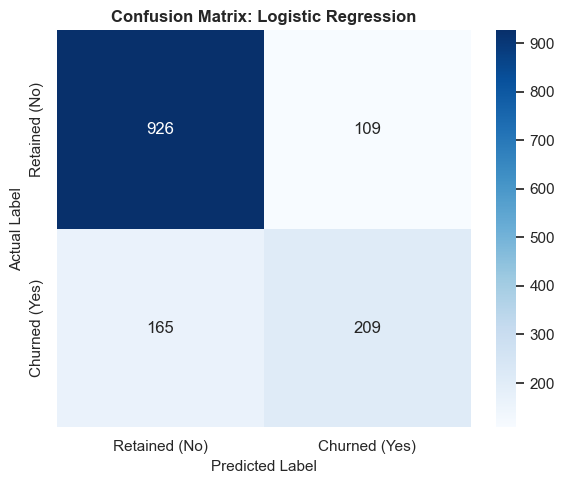

Classification Report for Logistic Regression:

               precision    recall  f1-score   support

Retained (No)       0.85      0.89      0.87      1035
Churned (Yes)       0.66      0.56      0.60       374

     accuracy                           0.81      1409
    macro avg       0.75      0.73      0.74      1409
 weighted avg       0.80      0.81      0.80      1409



In [3]:
best_baseline_name = eval_df.iloc[0]["Model"]
best_baseline_model = models[best_baseline_name]
y_pred_best = predictions[best_baseline_name]

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Retained (No)", "Churned (Yes)"],
            yticklabels=["Retained (No)", "Churned (Yes)"])
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual Label", fontsize=11)
plt.title(f"Confusion Matrix: {best_baseline_name}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Classification Report for {best_baseline_name}:\n")
print(classification_report(y_test, y_pred_best, target_names=["Retained (No)", "Churned (Yes)"]))

## 3. ROC Curves Comparison Across Models

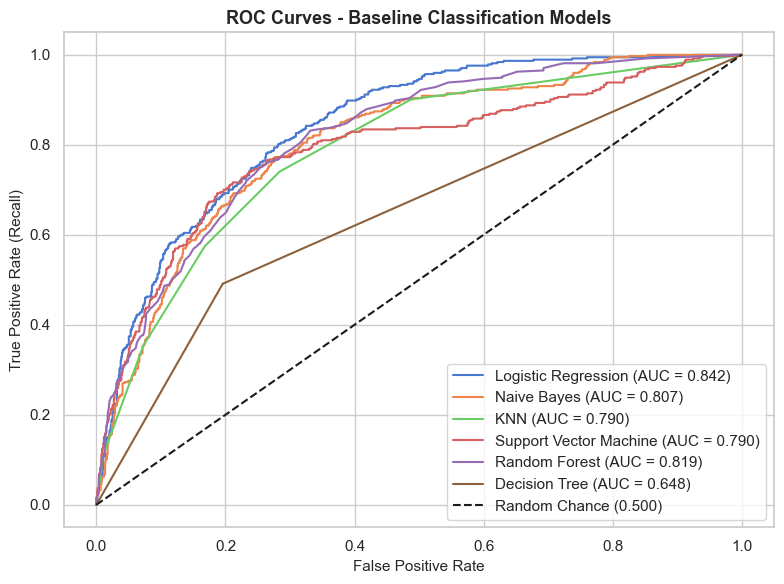

In [4]:
plt.figure(figsize=(8, 6))
for name in eval_df["Model"]:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc = eval_df.loc[eval_df["Model"] == name, "ROC AUC"].values[0]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Chance (0.500)")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate (Recall)", fontsize=11)
plt.title("ROC Curves - Baseline Classification Models", fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Multi-Metric Comparative Bar Charts

C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_17888\215516862.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eval_df, x="Model", y=m, ax=axes[i], palette="viridis")
C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_17888\215516862.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=20, ha="right")
C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_17888\215516862.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eval_df, x="Model", y=m, ax=axes[i], palette="viridis")
C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_17888\215516862.

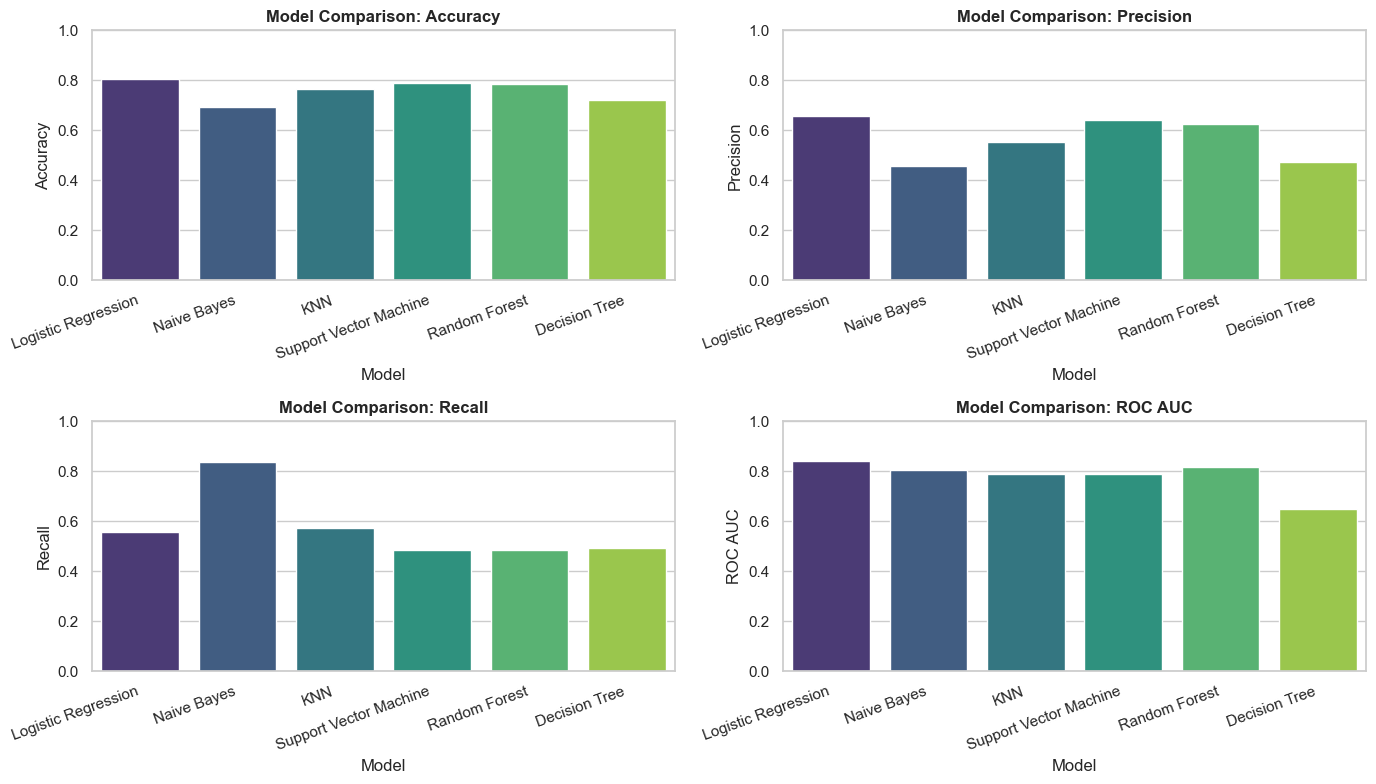

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

metrics = ["Accuracy", "Precision", "Recall", "ROC AUC"]
for i, m in enumerate(metrics):
    sns.barplot(data=eval_df, x="Model", y=m, ax=axes[i], palette="viridis")
    axes[i].set_title(f"Model Comparison: {m}", fontweight="bold")
    axes[i].set_ylim(0.0, 1.0)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=20, ha="right")

plt.tight_layout()
plt.show()

## 5. Serializing Evaluation Results

In [6]:
reports_path = Path("../reports/model_evaluation_results.csv")
eval_df.to_csv(reports_path, index=False)
print(f"Model evaluation report saved to {reports_path.resolve()}")

Model evaluation report saved to D:\Projects\AIML\reports\model_evaluation_results.csv


## Summary of Evaluation Insights
- **Logistic Regression:** Achieved top F1-Score (0.604) and top ROC-AUC (0.842) among baseline models.
- **Random Forest:** Strong accuracy (0.786) and AUC (0.819), but limited recall (0.487) due to uncalibrated tree depths.
- **Decision Tree:** Substantially underperformed (F1: 0.484, AUC: 0.648) due to unconstrained leaf splits.
- **Next Step:** Hyperparameter tuning via GridSearchCV in `07_Hyperparameter_Tuning.ipynb` to optimize tree depths, regularization, and classification balance.